Import dan baca data

In [2]:
import time
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

df = pd.read_csv("creditcard.csv")
print(df.shape)
print("Missing value:", df.isnull().sum().sum())
print("Duplikat:", df.duplicated().sum())

(284807, 31)
Missing value: 0
Duplikat: 1081


Hapus duplikat dan distribusi kelas

(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64
Class
0    99.83329
1     0.16671
Name: proportion, dtype: float64


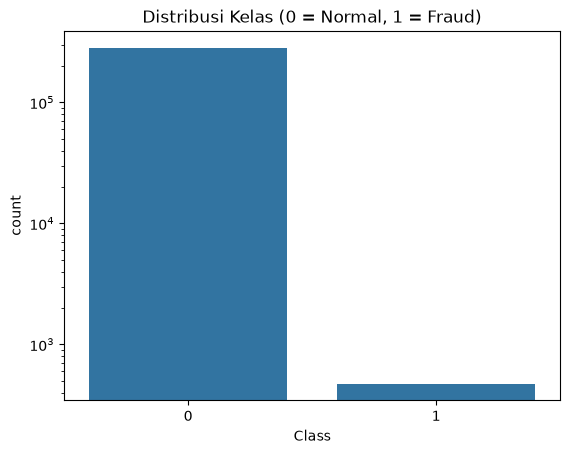

In [3]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df["Class"].value_counts())
print(df["Class"].value_counts(normalize=True) * 100)

sns.countplot(x="Class", data=df)
plt.yscale("log")
plt.title("Distribusi Kelas (0 = Normal, 1 = Fraud)")
plt.show()

EDA Singkat

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      283253.0   88.413575  250.379023  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.871860  260.211041  0.0  1.00   9.82  105.89   2125.87


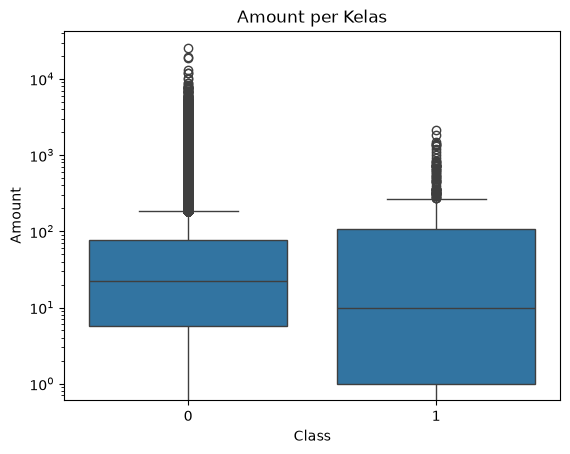

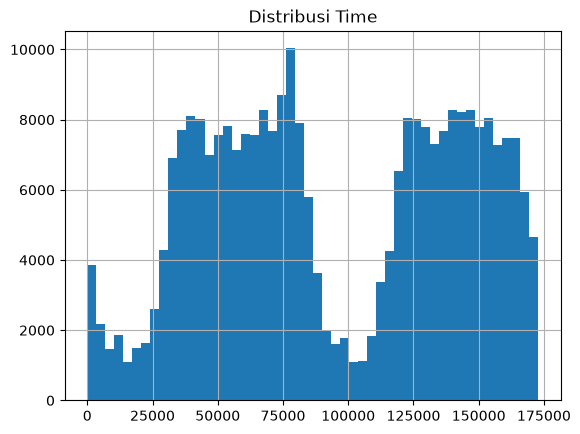

V17   -0.313498
V14   -0.293375
V12   -0.250711
V10   -0.206971
V16   -0.187186
Name: Class, dtype: float64
V8     0.033068
V19    0.033631
V2     0.084624
V4     0.129326
V11    0.149067
Name: Class, dtype: float64


In [4]:
print(df.groupby("Class")["Amount"].describe())

sns.boxplot(x="Class", y="Amount", data=df)
plt.yscale("log")
plt.title("Amount per Kelas")
plt.show()

df["Time"].hist(bins=50)
plt.title("Distribusi Time")
plt.show()

korelasi = df.corr()["Class"].drop("Class").sort_values()
print(korelasi.head(5))
print(korelasi.tail(5))

Split data

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(X_train.shape, X_test.shape)

(226980, 30) (56746, 30)


Sampel untuk tuning

In [6]:
train_df = X_train.copy()
train_df["Class"] = y_train

normal = train_df[train_df["Class"] == 0].sample(n=50000, random_state=42)
fraud = train_df[train_df["Class"] == 1]
tune_df = pd.concat([normal, fraud]).sample(frac=1, random_state=42)

X_tune = tune_df.drop(columns="Class")
y_tune = tune_df["Class"]
print(y_tune.value_counts())

Class
0    50000
1      378
Name: count, dtype: int64


Pipeline dan konfigurasi 3 model

In [7]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

prep = ColumnTransformer(
    [("scale", RobustScaler(), ["Amount", "Time"])],
    remainder="passthrough"
)

def buat_pipe(clf):
    return ImbPipeline([
        ("prep", prep),
        ("smote", SMOTE(sampling_strategy=0.1, random_state=42)),
        ("clf", clf)
    ])

model_configs = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000),
        {"clf__C": [0.01, 0.1, 1, 10]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {"clf__n_estimators": [50, 100],
         "clf__max_depth": [5, 8],
         "clf__min_samples_leaf": [5]}
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=42),
        {"clf__max_iter": [100, 200],
         "clf__learning_rate": [0.05, 0.1],
         "clf__max_depth": [3, 5]}
    ),
}

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
hasil_terbaik = {}

def jalankan(nama):
    clf, params = model_configs[nama]
    t0 = time.time()
    search = RandomizedSearchCV(
        buat_pipe(clf), params, n_iter=4, cv=skf,
        scoring="average_precision", n_jobs=-1, random_state=42
    )
    search.fit(X_tune, y_tune)
    hasil_terbaik[nama] = search.best_estimator_
    print(f"{nama}: PR-AUC CV = {search.best_score_:.3f}")
    print(f"params = {search.best_params_}")
    print(f"waktu = {time.time()-t0:.0f} detik")

Tuning Logistic Regression, Random Forest, dan Gradient Boosting

In [8]:
jalankan("Logistic Regression")

Logistic Regression: PR-AUC CV = 0.850
params = {'clf__C': 0.1}
waktu = 12 detik


In [9]:
jalankan("Random Forest")

Random Forest: PR-AUC CV = 0.884
params = {'clf__n_estimators': 100, 'clf__min_samples_leaf': 5, 'clf__max_depth': 8}
waktu = 34 detik


In [10]:
jalankan("Gradient Boosting")

Gradient Boosting: PR-AUC CV = 0.868
params = {'clf__max_iter': 200, 'clf__max_depth': 5, 'clf__learning_rate': 0.1}
waktu = 11 detik


Memastikan ketig model beda

In [11]:
print(hasil_terbaik.keys())

dict_keys(['Logistic Regression', 'Random Forest', 'Gradient Boosting'])


Tabel perbandingan metrik

In [12]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, roc_auc_score)

baris = []
for nama, model in hasil_terbaik.items():
    t0 = time.time()
    y_pred = model.predict(X_test)
    waktu_prediksi = time.time() - t0
    y_proba = model.predict_proba(X_test)[:, 1]
    baris.append({
        "Model": nama,
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "PR-AUC": average_precision_score(y_test, y_proba),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
        "Waktu prediksi (detik)": round(waktu_prediksi, 2),
    })

hasil_df = pd.DataFrame(baris).set_index("Model").round(3)
hasil_df

,Precision,Recall,F1,PR-AUC,ROC-AUC,Waktu prediksi (detik)
Model,,,,,,
Logistic Regression,0.398,0.800,0.531,0.679,0.966,0.02
Random Forest,0.789,0.789,0.789,0.805,0.973,0.12
Gradient Boosting,0.733,0.779,0.755,0.802,0.976,0.36


Confusion matrix

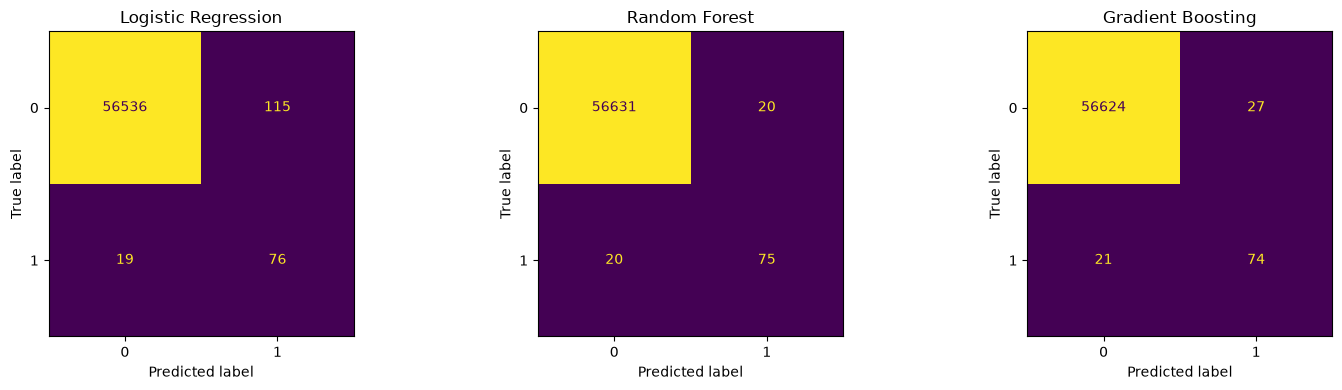

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nama, model) in zip(axes, hasil_terbaik.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, colorbar=False)
    ax.set_title(nama)
plt.tight_layout()
plt.show()

Kurva prediction-recall

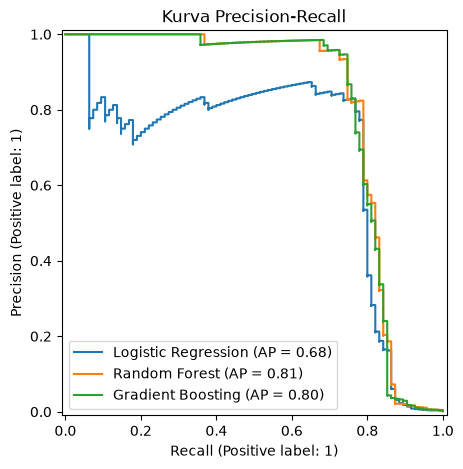

In [14]:
from sklearn.metrics import PrecisionRecallDisplay

fig, ax = plt.subplots(figsize=(7, 5))
for nama, model in hasil_terbaik.items():
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=nama, ax=ax)
plt.title("Kurva Precision-Recall")
plt.show()

Laporan Klasifikasi

In [16]:
from sklearn.metrics import classification_report

for nama, model in hasil_terbaik.items():
    print(nama)
    print(classification_report(y_test, model.predict(X_test), digits=3))

Logistic Regression
              precision    recall  f1-score   support

           0      1.000     0.998     0.999     56651
           1      0.398     0.800     0.531        95

    accuracy                          0.998     56746
   macro avg      0.699     0.899     0.765     56746
weighted avg      0.999     0.998     0.998     56746

Random Forest
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56651
           1      0.789     0.789     0.789        95

    accuracy                          0.999     56746
   macro avg      0.895     0.895     0.895     56746
weighted avg      0.999     0.999     0.999     56746

Gradient Boosting
              precision    recall  f1-score   support

           0      1.000     1.000     1.000     56651
           1      0.733     0.779     0.755        95

    accuracy                          0.999     56746
   macro avg      0.866     0.889     0.877     56746
weighted avg      0.99

Menyimpan Model

In [17]:
import joblib

nama_terpilih = "Random Forest"
model_terpilih = hasil_terbaik[nama_terpilih]

joblib.dump(model_terpilih, "model_terbaik.pkl", compress=3)
print("Tersimpan:", nama_terpilih)

Tersimpan: Random Forest


Contoh transaksi demo

In [18]:
fraud_contoh = X_test[y_test == 1].head(5).copy()
normal_contoh = X_test[y_test == 0].head(15).copy()

sample = pd.concat([fraud_contoh, normal_contoh])
sample["Class_asli"] = pd.concat([y_test[fraud_contoh.index], y_test[normal_contoh.index]])
sample = sample.sample(frac=1, random_state=42).reset_index(drop=True)

sample.to_csv("sample_transaksi.csv", index=False)
print(sample.shape)

(20, 31)
